# Rebalanceo por beneficio frente a costo

MVP M2: verificación sintética, no validación empírica ni producto.

Hipótesis: el filtro reduce rotación frente a MV mensual. No presupone mejorar Sharpe. Ventana 252, paso 21, gamma 5, shrinkage diagonal fijo 0.2, 20 seeds y costos 0/10/50 bps. Todas las decisiones usan r[t-252:t].

In [1]:
import json
import pandas as pd
from IPython.display import display, Image
metadata=json.load(open('results/metadata.json'))
display(metadata)

{'date': '2026-10-12 America/Bogota',
 'source_commit': '558bde13013df8a446fbb6acf4c69447be88dd03',
 'config': {'window': 252,
  'step': 21,
  'cost_bps': 10.0,
  'gamma': 5.0,
  'shrink': 0.2},
 'seeds': [41,
  42,
  43,
  44,
  45,
  46,
  47,
  48,
  49,
  50,
  51,
  52,
  53,
  54,
  55,
  56,
  57,
  58,
  59,
  60],
 'days': 1260,
 'regimes': ['stationary', 'switch'],
 'costs_bps': [0, 10, 50],
 'runs': 720,
 'bootstrap_seed': 20261012,
 'bootstrap_replicates': 5000,
 'total_seconds': 30.25810975400009,
 'python': '3.12.14',
 'numpy': '2.3.5',
 'scipy': '1.17.0',
 'pandas': '2.2.3',
 'os': 'Linux-6.18.44-x86_64-with-glibc2.39',
 'cpu': 'AMD EPYC 9V74 80-Core Processor',
 'scope': 'synthetic research prototype, not production'}

## Baseline numérico y brecha
Se conserva el solver diario original como legacy_mv. La variante corregida normaliza el objetivo y verifica una brecha de primer orden para el QP convexo. Una tolerancia absoluta inadecuada no equivale a evidencia de optimización.

In [2]:
display(pd.DataFrame(json.load(open('results/solver_diagnostic.json'))))
print(open('results/legacy_stdout.txt').read())

  estrategia  retorno_anual  vol_anual  Sharpe  rotacion_total
     iguales         10.09%     11.63%    0.87            2.14
min_varianza         10.09%     11.63%    0.87            2.14



,legacy,weights,variance,relative_variance,daily_kkt_gap
0,True,"[0.2, 0.2, 0.2, 0.2, 0.2]",0.000057,1.000000,6.445407e-05
1,False,"[0.0, 7.917281136999779e-17, 0.839593331707474...",0.000025,0.433704,6.776264e-21


## Experimento pareado
Retornos sintéticos gaussianos con medias distintas por activo; régimen estacionario y cambio de volatilidades a mitad de muestra. La regla omite diferencias esperadas de retorno: este supuesto es una limitación explícita. Costos sobre notional comprado + vendido, antes del retorno. No hay selección de parámetros por resultados.

,regime,cost_bps,strategy,seconds,annual_return,volatility,sharpe,sortino,max_drawdown,turnover,cost_drag_bps,terminal_wealth
6,stationary,10.0,equal,0.00573,0.05848,0.10242,0.60334,0.89478,-0.17052,1.11814,11.18137,1.25377
7,stationary,10.0,gate,0.06576,0.05757,0.08029,0.69980,1.03996,-0.12729,0.76654,7.66538,1.25710
8,stationary,10.0,gate_no_shrink,0.06488,0.05540,0.07465,0.71529,1.06302,-0.11629,0.99952,9.99518,1.24791
9,stationary,10.0,legacy_mv,0.02755,0.05848,0.10242,0.60334,0.89478,-0.17052,1.11814,11.18137,1.25377
10,stationary,10.0,monthly_mv,0.06280,0.04811,0.06915,0.70524,1.04771,-0.11002,3.18012,31.80119,1.20902
11,stationary,10.0,static_mv,0.00676,0.04790,0.06958,0.69193,1.02514,-0.10948,1.07992,10.79920,1.20739
24,switch,10.0,equal,0.00564,0.05801,0.10208,0.59515,0.88269,-0.17034,1.11546,11.15462,1.25225
25,switch,10.0,gate,0.06699,0.05522,0.08278,0.65194,0.96576,-0.13337,0.84091,8.40911,1.24415
26,switch,10.0,gate_no_shrink,0.06204,0.05420,0.07789,0.67479,1.00118,-0.12420,1.01808,10.18082,1.24118
27,switch,10.0,legacy_mv,0.02717,0.05801,0.10208,0.59515,0.88269,-0.17034,1.11546,11.15462,1.25225


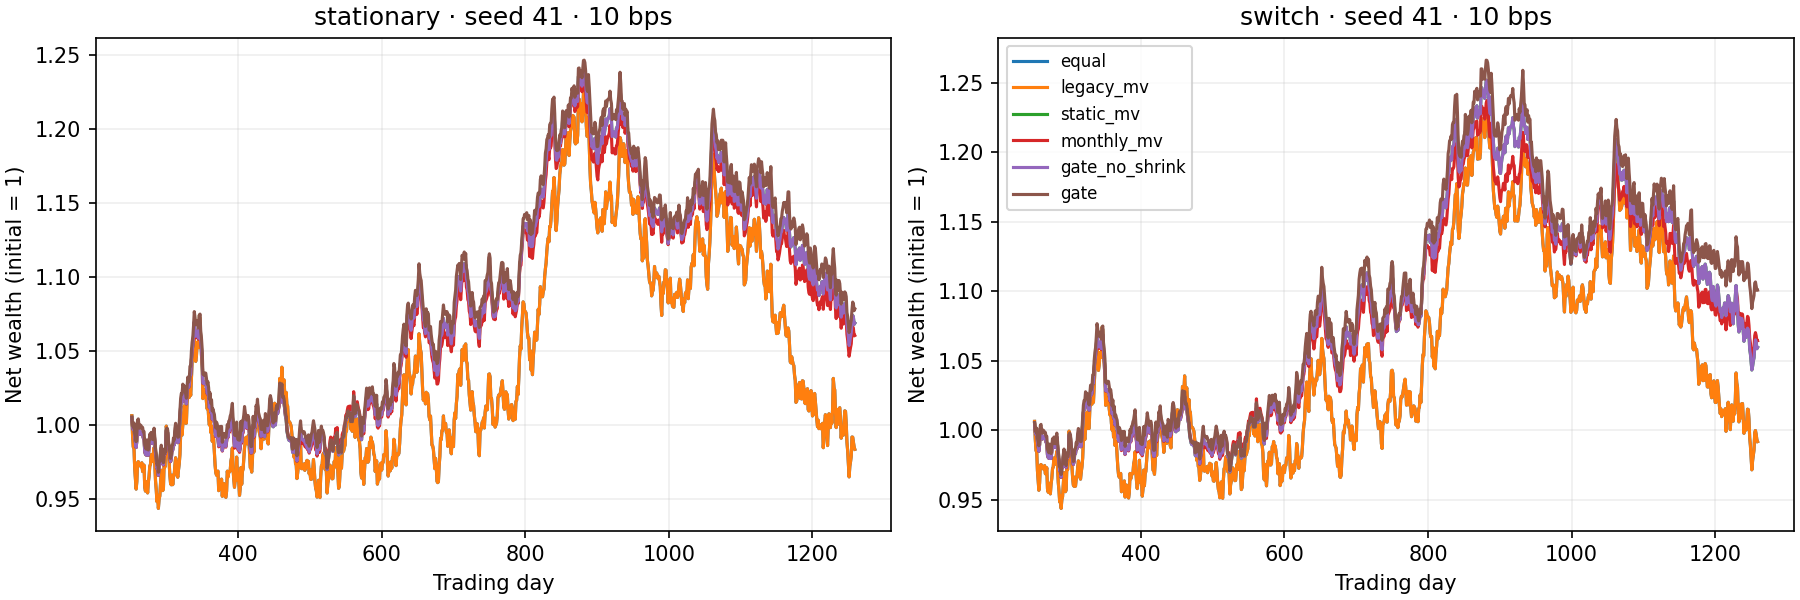

In [3]:
summary=pd.read_csv('results/summary.csv')
display(summary[summary.cost_bps==10].round(5))
display(Image(filename='results/wealth.png'))

## Incertidumbre y ablaciones negativas
Bootstrap pareado de diferencias entre seeds, 5000 réplicas, seed 20261012; intervalos percentiles descriptivos, sin corrección por comparaciones múltiples. No son intervalos de rendimiento futuro de mercados. El filtro no mejora significativamente el Sharpe frente a MV mensual; el shrinkage no añade beneficio de Sharpe en esta muestra.

In [4]:
paired=pd.read_csv('results/paired_bootstrap.csv')
display(paired[(paired.cost_bps==10)&(paired.metric=='sharpe')])
display(pd.read_csv('results/scaling.csv'))
c=json.load(open('results/coverage.json'))
display(c['totals'])

,regime,cost_bps,baseline,metric,mean_delta,low,high,positive_fraction
12,stationary,10.0,equal,sharpe,0.096463,0.025941,0.172870,0.65
16,stationary,10.0,monthly_mv,sharpe,-0.005445,-0.087952,0.071198,0.50
20,stationary,10.0,gate_no_shrink,sharpe,-0.015490,-0.057315,0.025461,0.40
48,switch,10.0,equal,sharpe,0.056785,-0.025907,0.147108,0.55
52,switch,10.0,monthly_mv,sharpe,-0.055894,-0.156064,0.038363,0.40
56,switch,10.0,gate_no_shrink,sharpe,-0.022857,-0.066019,0.018329,0.40


,days,assets,seconds,python_peak_bytes
0,630,5,0.161675,138978
1,1260,5,0.408077,366733
2,2520,5,1.050949,817929


{'covered_lines': 101,
 'num_statements': 103,
 'percent_covered': 97.16312056737588,
 'percent_covered_display': '97',
 'missing_lines': 2,
 'excluded_lines': 0,
 'percent_statements_covered': 98.05825242718447,
 'percent_statements_covered_display': '98',
 'num_branches': 38,
 'num_partial_branches': 2,
 'covered_branches': 36,
 'missing_branches': 2,
 'percent_branches_covered': 94.73684210526316,
 'percent_branches_covered_display': '95'}

## Conclusión
La contribución defendible es la corrección numérica y un benchmark auditable del intercambio entre costos y riesgo. No hay un algoritmo nuevo para la literatura. Sin datos reales, impacto, impuestos, ejecución, liquidez ni validación independiente. Consulte informe.md y referencias.bib.